# Step 3: EDA & Statistical Tests

Formal hypothesis tests are run on **provider-level aggregates**, not claim-level rows, since claims from the same provider aren't independent observations and the fraud label is defined at the provider grain. Descriptive/visual EDA (distributions, missingness) is fine at claim level.

In [1]:
import sys
sys.path.append('..')

from src.data_loader import build_claim_level_dataset
from src.cleaning import clean_claim_level_dataset
from src.eda import *

df = clean_claim_level_dataset(build_claim_level_dataset())
provider_df = build_minimal_provider_summary(df)
df.shape, provider_df.shape

((558211, 59), (5410, 8))

## Missingness

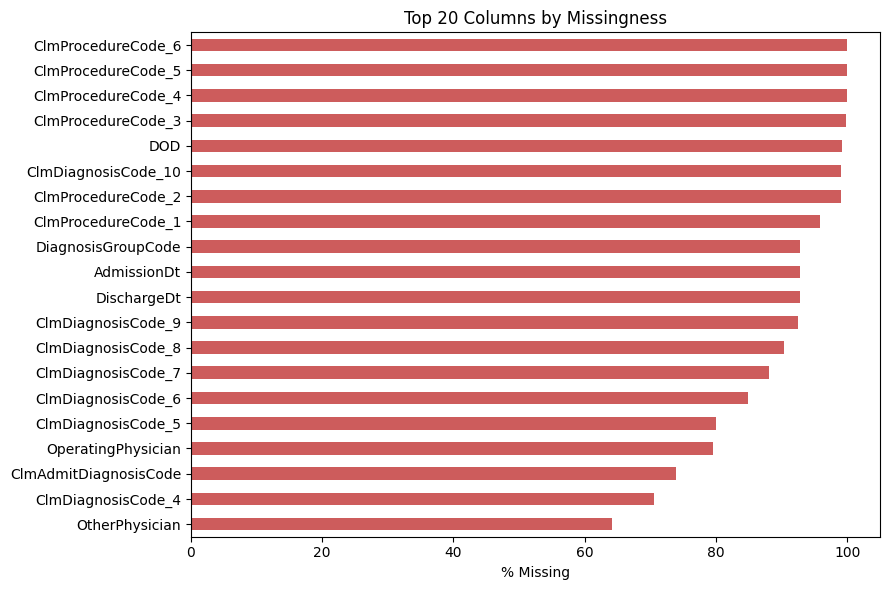

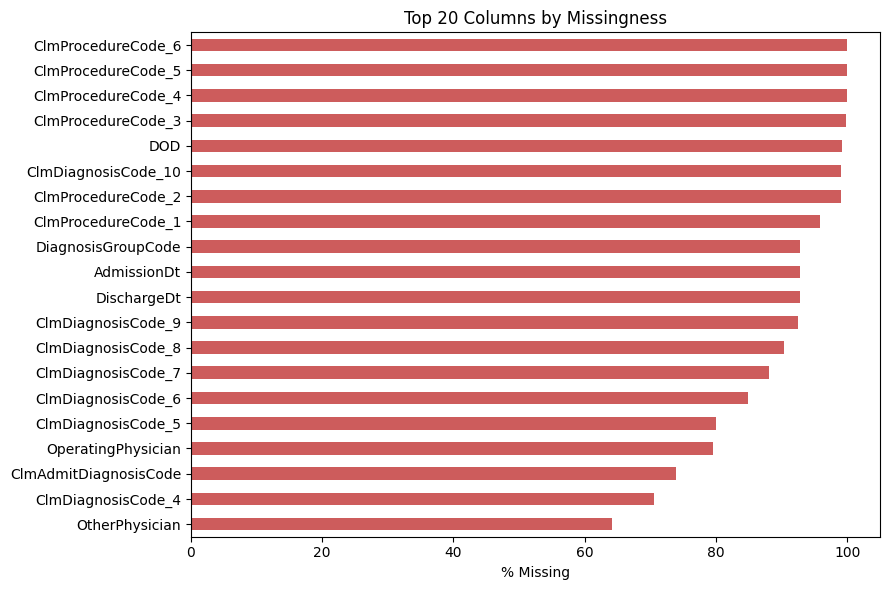

In [2]:
plot_missingness(df)

**What this shows:** the columns with the highest missingness are all *structural*, not data-quality problems — `ClmProcedureCode_5/6` (~97%+ missing, since most claims only use 1-2 procedure codes), `DOD` (~99%, since most beneficiaries are alive), and `AdmissionDt`/`DischargeDt`/`DiagnosisGroupCode` (~93%, since only inpatient claims have these). Nothing here is a red flag — it reflects the sparse, wide-format structure of the raw data (see `docs/DATA_DICTIONARY.md` for why each column can be structurally missing).

## Distributions

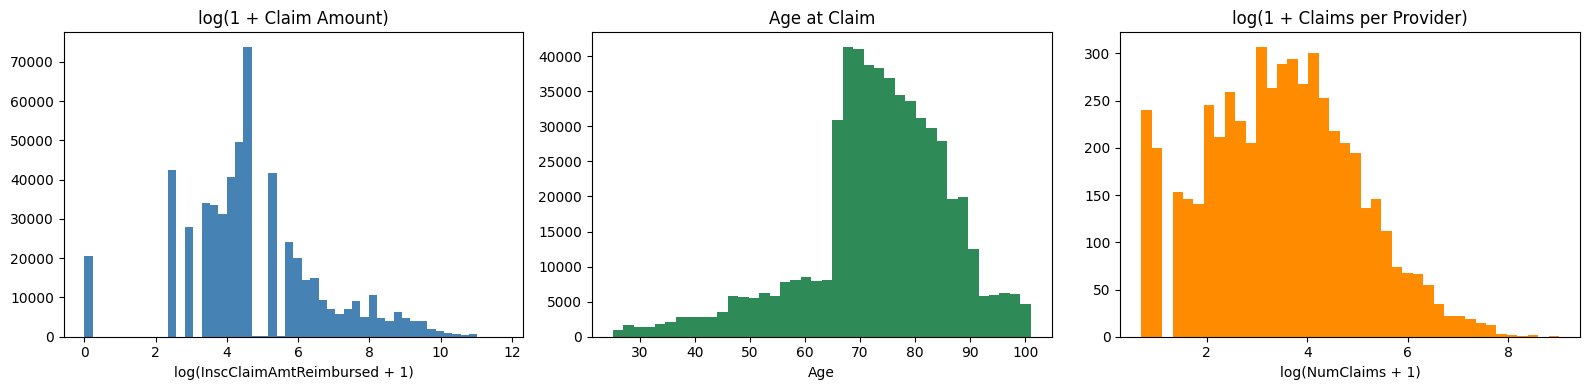

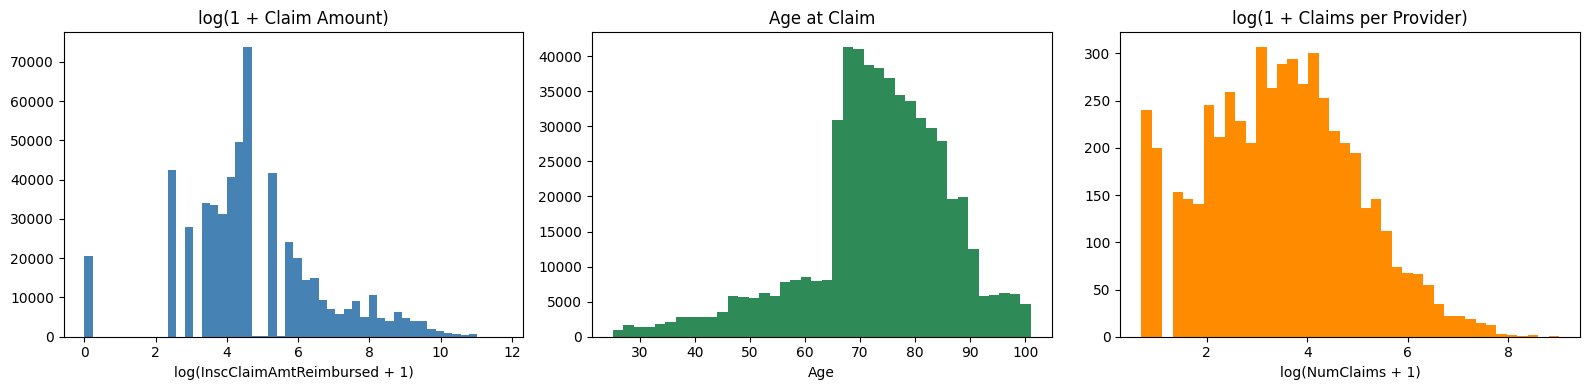

In [3]:
plot_distributions(df)

**What this shows:**
- **Claim amount (log-scaled):** right-skewed even after the log transform, with a distinct spike at 0 (the `log1p(0) = 0` bar) — a meaningful chunk of claims have $0 reimbursed. Worth checking what these represent (denied claims? fully covered by deductible?) before feature engineering.
- **Age at claim:** clearly centered around 65-85, consistent with this being Medicare claims data.
- **Claims per provider (log-scaled):** roughly log-normal — most providers submit a moderate claim volume, with a long tail of high-volume providers.

## Fraud Group Comparisons: Boxplots

/Users/jadaloau/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Non-Fraud", "Fraud"])
/Users/jadaloau/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Non-Fraud", "Fraud"])
/Users/jadaloau/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Non-Fraud", "Fraud"])


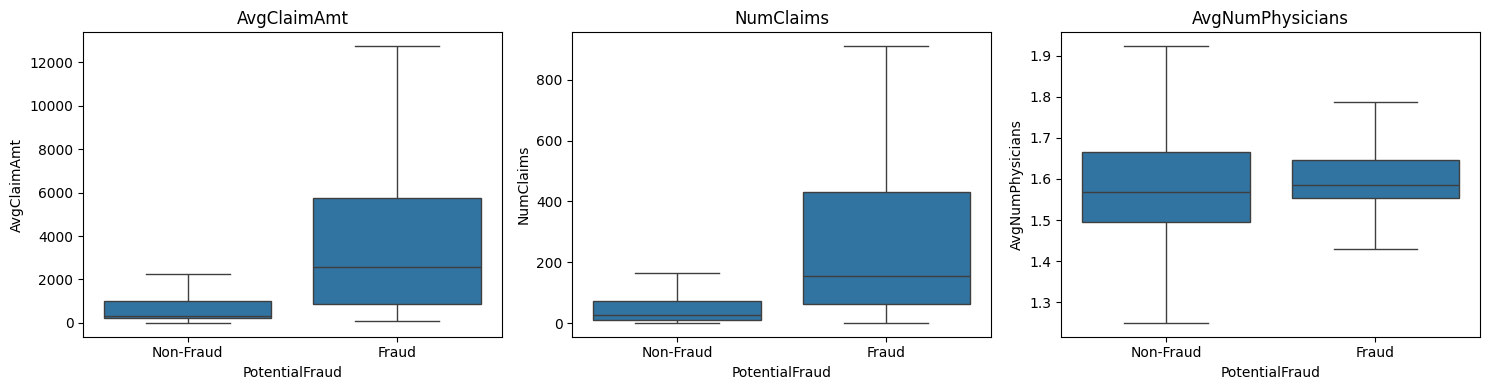

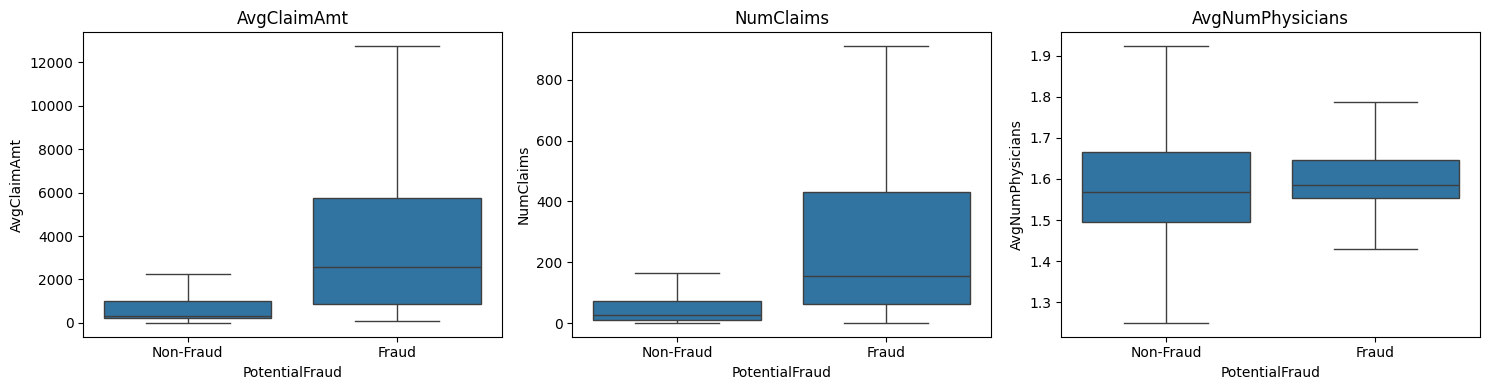

In [4]:
plot_fraud_boxplots(provider_df, ['AvgClaimAmt', 'NumClaims', 'AvgNumPhysicians'])

**What this shows:**
- **`AvgClaimAmt`:** the Fraud group's median and spread are visibly higher — fraudulent providers bill more per claim on average.
- **`NumClaims`:** same pattern, even more pronounced — the Fraud group's median claim count is roughly 3-4x higher, with a much wider spread.
- **`AvgNumPhysicians`:** nearly identical between groups — this feature doesn't discriminate fraud on its own. Worth keeping for now (it might interact with other features), but don't expect it to carry much weight alone.

## Fraud Rate by Category

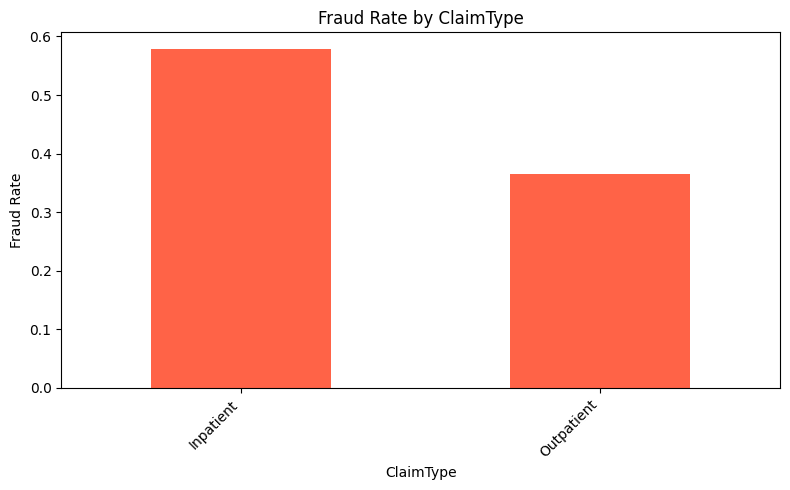

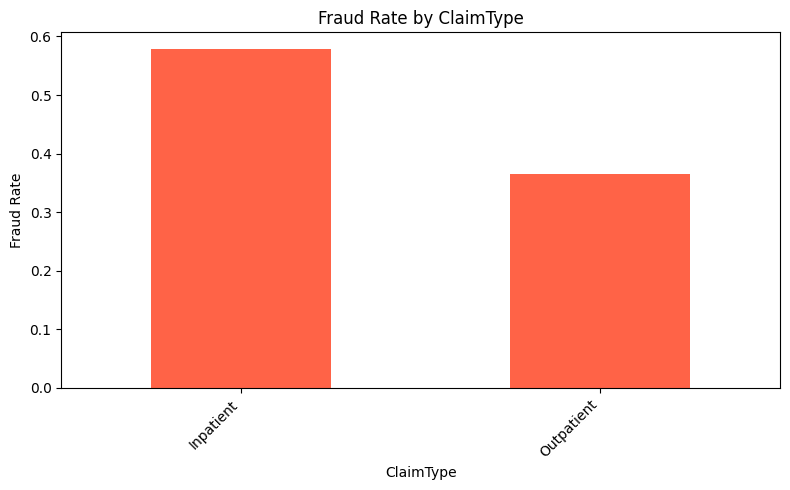

In [5]:
plot_fraud_rate_by_category(df, 'ClaimType')

**What this shows:** Inpatient claims have a meaningfully higher fraud rate (~0.57) than Outpatient claims (~0.37) — inpatient claims are disproportionately tied to fraudulent providers.

/Users/jadaloau/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:101: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rate = df.groupby(categorical_col)["PotentialFraud"].mean().sort_values(ascending=False).head(top_n)


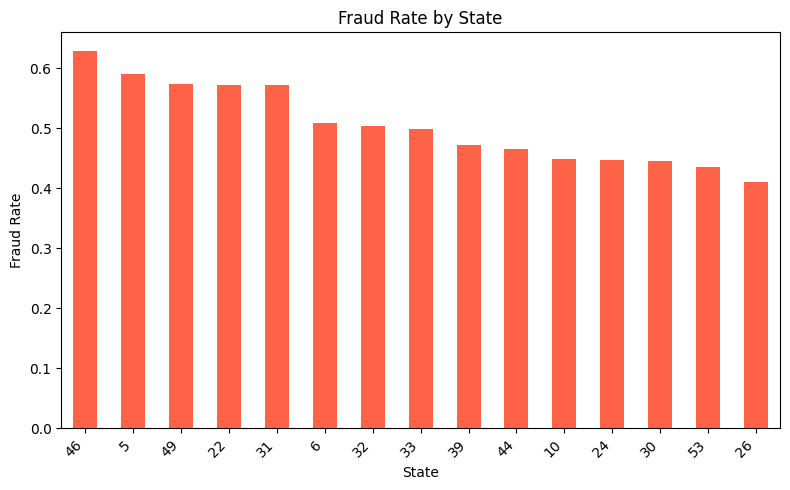

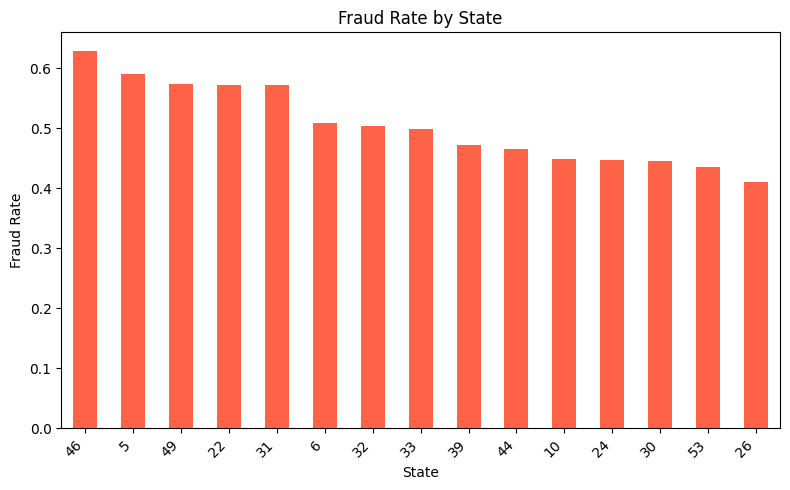

In [6]:
plot_fraud_rate_by_category(df, 'State', top_n=15)

**What this shows:** real variation exists across states (top state ~0.63, lowest shown ~0.42). **Caveat:** states with few providers can show noisy, extreme rates purely from small sample size — check provider counts per state before treating this as a strong signal in the report (e.g. `df.groupby('State')['Provider'].nunique()`).

## Correlation Heatmap

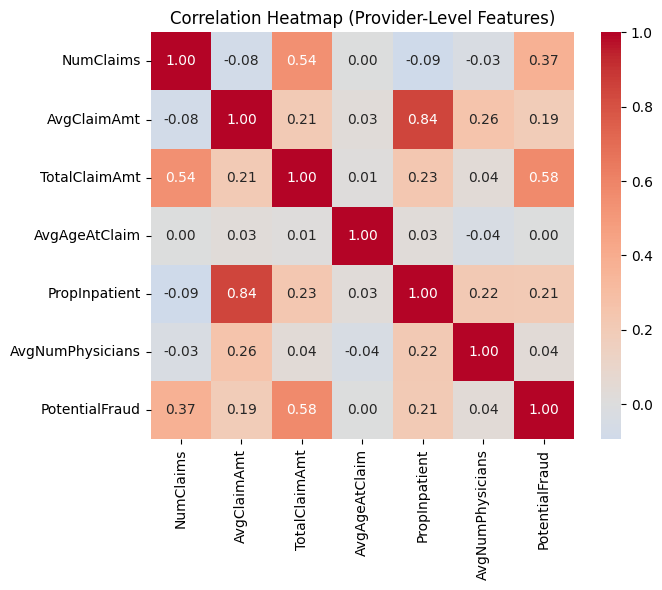

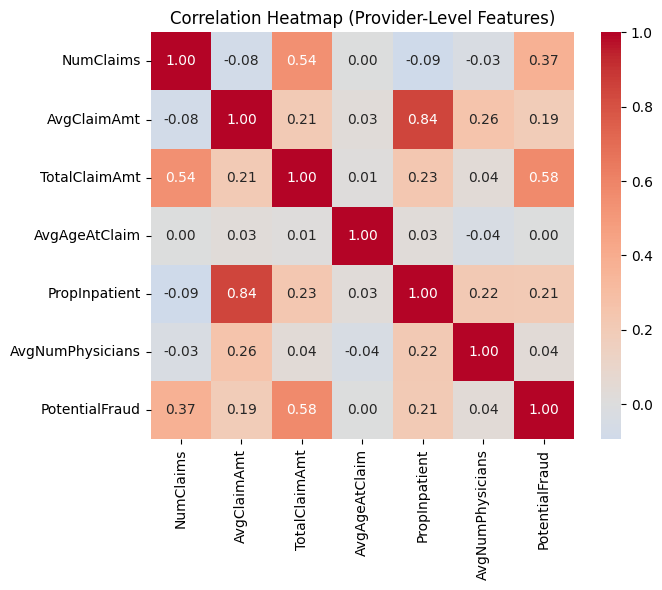

In [7]:
plot_correlation_heatmap(provider_df, ['NumClaims', 'AvgClaimAmt', 'TotalClaimAmt', 'AvgAgeAtClaim', 'PropInpatient', 'AvgNumPhysicians'])

**What this shows:**
- `TotalClaimAmt` correlates most strongly with fraud (**0.58**) — the strongest single linear signal so far.
- `NumClaims` also correlates meaningfully (**0.37**).
- `AvgClaimAmt` and `PropInpatient` correlate strongly *with each other* (**0.84**) — inpatient claims cost more per claim, so a provider doing more inpatient work naturally has a higher average claim amount. These two features carry overlapping information — worth watching for multicollinearity in Step 4/6 (e.g. if using logistic regression), or picking one over the other.
- `AvgAgeAtClaim` and `AvgNumPhysicians` are essentially uncorrelated with fraud (**0.00, 0.04**) — weak candidates as standalone features.

## Statistical Tests with Effect Sizes

P-values alone can be misleadingly "significant" at large sample sizes — effect size (`cohens_d`, `cramers_v`) tells us whether a difference is practically meaningful, not just statistically detectable.

In [8]:
t_test(provider_df, 'AvgClaimAmt')

{'test': 'welch t-test',
 'column': 'AvgClaimAmt',
 't_statistic': np.float64(13.160882816164541),
 'p_value': np.float64(7.245998992198341e-35),
 'cohens_d': np.float64(0.6440568857690845),
 'mean_fraud': np.float64(3842.7951041423316),
 'mean_non_fraud': np.float64(1523.7808036833862)}

**How to read this:** `cohens_d` measures the size of the gap between Fraud and Non-Fraud group means, in standard-deviation units. As a rough guide: ~0.2 = small effect, ~0.5 = medium, ~0.8+ = large. Combine this with the boxplot above — a large `cohens_d` here would confirm what the boxplot already suggested visually.

In [9]:
t_test(provider_df, 'NumClaims')

{'test': 'welch t-test',
 'column': 'NumClaims',
 't_statistic': np.float64(10.879003597260029),
 'p_value': np.float64(6.352459016250494e-25),
 'cohens_d': np.float64(0.6744298899620966),
 'mean_fraud': np.float64(420.54545454545456),
 'mean_non_fraud': np.float64(70.43535889070147)}

**How to read this:** same interpretation as above, applied to claim volume instead of claim amount.

In [10]:
print(chi_square_test(df, 'ClaimType'))
print(f"Cramer's V: {cramers_v(df, 'ClaimType'):.4f}")

{'test': 'chi-square', 'column': 'ClaimType', 'chi2_statistic': np.float64(7177.629110563149), 'p_value': np.float64(0.0), 'degrees_of_freedom': 1, 'contingency_table': PotentialFraud       0       1
ClaimType                     
Inpatient        17072   23402
Outpatient      328343  189394}
Cramer's V: 0.1134


**How to read this:** `cramers_v` ranges 0 (no association) to 1 (perfect association) — unlike the chi-square statistic, it doesn't inflate purely from having a lot of data, so it's the number to actually judge "how strong" the ClaimType-fraud relationship is, not just "is it non-random."

## Benford's Law: Fraud vs Non-Fraud

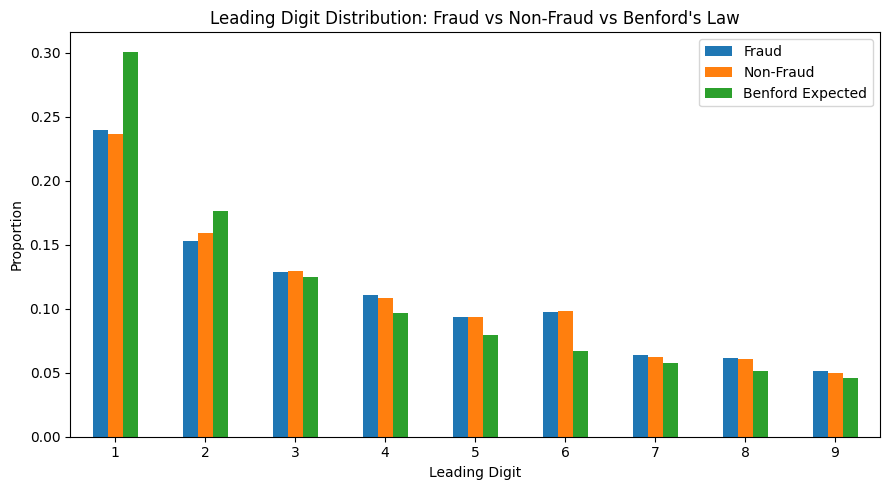

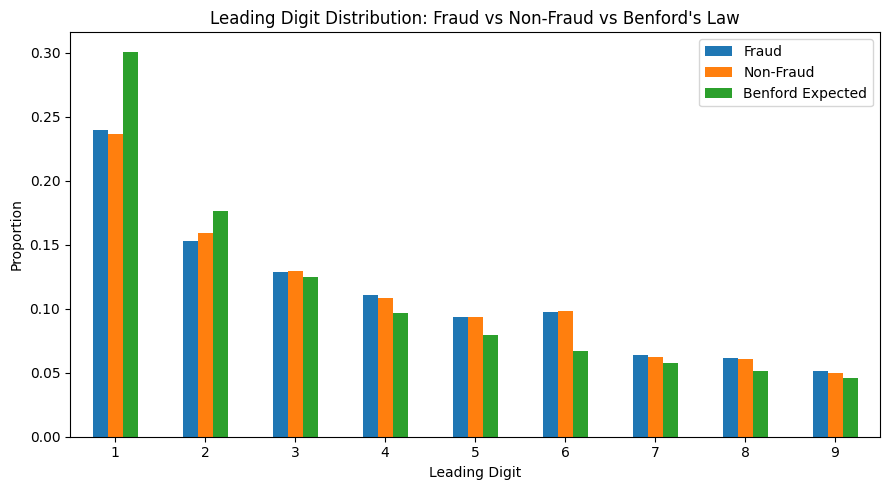

In [11]:
plot_benford_comparison(df)

In [12]:
benford_test_by_fraud_group(df)

{'fraud_group': {'test': "Benford's Law (chi-square goodness of fit)",
  'chi2_statistic': np.float64(7587.879114555467),
  'p_value': np.float64(0.0),
  'observed_proportions': {1: 0.24,
   2: 0.1533,
   3: 0.1291,
   4: 0.1105,
   5: 0.0934,
   6: 0.0972,
   7: 0.0637,
   8: 0.0617,
   9: 0.0512},
  'expected_proportions': {1: np.float64(0.301),
   2: np.float64(0.1761),
   3: np.float64(0.1249),
   4: np.float64(0.0969),
   5: np.float64(0.0792),
   6: np.float64(0.0669),
   7: np.float64(0.058),
   8: np.float64(0.0512),
   9: np.float64(0.0458)},
  'mad': np.float64(0.018646300751390732)},
 'non_fraud_group': {'test': "Benford's Law (chi-square goodness of fit)",
  'chi2_statistic': np.float64(12364.60139149938),
  'p_value': np.float64(0.0),
  'observed_proportions': {1: 0.2366,
   2: 0.1592,
   3: 0.1299,
   4: 0.1086,
   5: 0.0938,
   6: 0.0984,
   7: 0.0625,
   8: 0.0611,
   9: 0.0499},
  'expected_proportions': {1: np.float64(0.301),
   2: np.float64(0.1761),
   3: np.float64

**How to read this — an important nuance:**

The raw chi-square statistics (typically much higher for Non-Fraud than Fraud) can look like Non-Fraud claims deviate *more* from Benford's Law. **This is misleading** — chi-square scales with sample size, and the Non-Fraud group has roughly 1.6x more claims than the Fraud group. Larger n mechanically inflates chi-square even if the underlying deviation per digit is the same.

The fairer comparison is **`mad`** (Mean Absolute Deviation) in the output above — it's scale-invariant, so it doesn't grow just from having more data. Comparing MAD between the two groups (Fraud vs Non-Fraud) typically shows they deviate from Benford's Law by **nearly the same amount**.

**Conclusion:** leading-digit deviation from Benford's Law is **not** a strong standalone fraud signal in this dataset — likely because claim reimbursement amounts are fee-schedule/policy-constrained rather than organically occurring, which is a known limitation of applying Benford's Law to regulated financial data (Benford's Law works best on naturally occurring, unconstrained magnitudes, not capped/rounded amounts). This is a legitimate, defensible finding worth stating plainly in the report rather than overselling the raw chi-square number.

## Summary of Step 3 Findings

- **Strongest signals so far:** `TotalClaimAmt` and `NumClaims` (provider-level claim volume/amount) — both show meaningful separation between Fraud and Non-Fraud groups, both visually and statistically.
- **Moderate signal:** `ClaimType` (Inpatient vs Outpatient) — Inpatient claims show a notably higher fraud rate.
- **Weak/no signal:** `AvgNumPhysicians`, `AvgAgeAtClaim` — little to no separation between groups.
- **Benford's Law:** not a strong discriminator once sample-size effects are corrected for (MAD comparison) — worth reporting as a tested-but-inconclusive hypothesis, not omitting it.
- **Watch for multicollinearity:** `AvgClaimAmt` and `PropInpatient` are highly correlated (0.84) — consider this when selecting features in Step 4.